In [1]:
print("My Data Science Portfolio")
print("Project 1:Student Performance Analysis")

My Data Science Portfolio
Project 1:Student Performance Analysis


In [2]:
project_name="Student Performance Analysis"
student_count=100
average_score=85.0

print(project_name)
print(student_count)
print(average_score)

Student Performance Analysis
100
85.0


In [3]:
scores=[65, 78, 82, 55, 90, 71, 88, 60, 95, 76]

print(scores)

average=sum(scores)/len(scores)

print("Average scores:", average)

[65, 78, 82, 55, 90, 71, 88, 60, 95, 76]
Average scores: 76.0


In [4]:
scores=[65, 78, 82, 55, 90, 71, 88, 60, 99, 76]

highest_score=max(scores)
lowest_score=min(scores)

print("Highest score:",highest_score)
print("Lowest score:", lowest_score)

Highest score: 99
Lowest score: 55


In [5]:
scores=[65, 78, 82, 55, 90, 71, 88, 60, 95, 76]

passed=0

for score in scores:
  if score>=70:
    passed=passed+1

print("Students who passed:", passed)
print("Students who failed:", len(scores)-passed)

Students who passed: 7
Students who failed: 3


In [6]:
scores=[65, 78, 82, 55, 90, 71, 88, 60, 95, 76]

passed=0

for score in scores:
  if score >= 70:
    passed=passed+1

pass_rate=(passed/len(scores))*100

print("Number of students:", len(scores))
print("Students who passed:", passed)
print("Pass rate:", pass_rate, "%")

Number of students: 10
Students who passed: 7
Pass rate: 70.0 %


In [7]:
import pandas as pd

data={
    "Student":["Ann","Brian","Carol","David","Eva"],
    "Maths":[78, 45, 89, 62, 55],
    "English":[82, 60, 91, 70, 67]
}

df=pd.DataFrame(data)

print(df)


  Student  Maths  English
0     Ann     78       82
1   Brian     45       60
2   Carol     89       91
3   David     62       70
4     Eva     55       67


In [8]:
print(df.describe())

           Maths    English
count   5.000000   5.000000
mean   65.800000  74.000000
std    17.683325  12.389512
min    45.000000  60.000000
25%    55.000000  67.000000
50%    62.000000  70.000000
75%    78.000000  82.000000
max    89.000000  91.000000


In [9]:
maths_top=df.loc[df["Maths"].idxmax()]
english_top=df.loc[df["English"].idxmax()]

print("Top Maths student:")
print(maths_top)

print("\nTop English student:")
print(english_top)

maths_lowest=df.loc[df["Maths"].idxmin()]
english_lowest=df.loc[df["English"].idxmin()]

print("\nLowest Maths scorer:")
print(maths_lowest)

print("\nLowest English scorer:")
print(english_lowest)

Top Maths student:
Student    Carol
Maths         89
English       91
Name: 2, dtype: object

Top English student:
Student    Carol
Maths         89
English       91
Name: 2, dtype: object

Lowest Maths scorer:
Student    Brian
Maths         45
English       60
Name: 1, dtype: object

Lowest English scorer:
Student    Brian
Maths         45
English       60
Name: 1, dtype: object


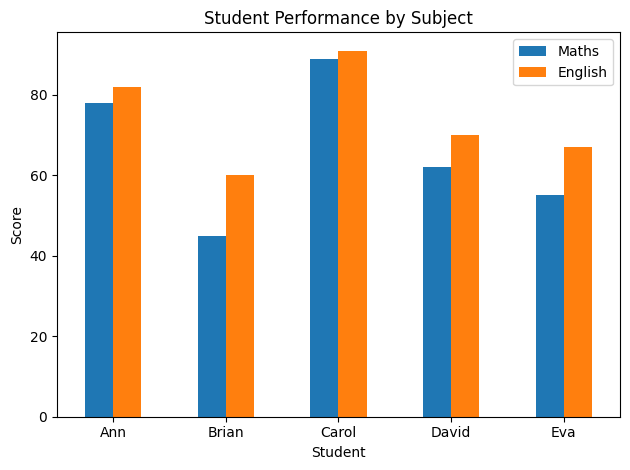

In [10]:
import matplotlib.pyplot as plt

df.plot(
    x="Student",
    y=["Maths","English"],
    kind="bar"
)

plt.title("Student Performance by Subject")
plt.xlabel("Student")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
df["Average"]=df[["Maths","English"]].mean(axis=1)

print(df)

  Student  Maths  English  Average
0     Ann     78       82     80.0
1   Brian     45       60     52.5
2   Carol     89       91     90.0
3   David     62       70     66.0
4     Eva     55       67     61.0


In [12]:
df["Rank"]=df["Average"].rank(
    ascending=False,
    method="min"
).astype(int)

df=df.sort_values("Average",ascending=False)

print(df)

  Student  Maths  English  Average  Rank
2   Carol     89       91     90.0     1
0     Ann     78       82     80.0     2
3   David     62       70     66.0     3
4     Eva     55       67     61.0     4
1   Brian     45       60     52.5     5


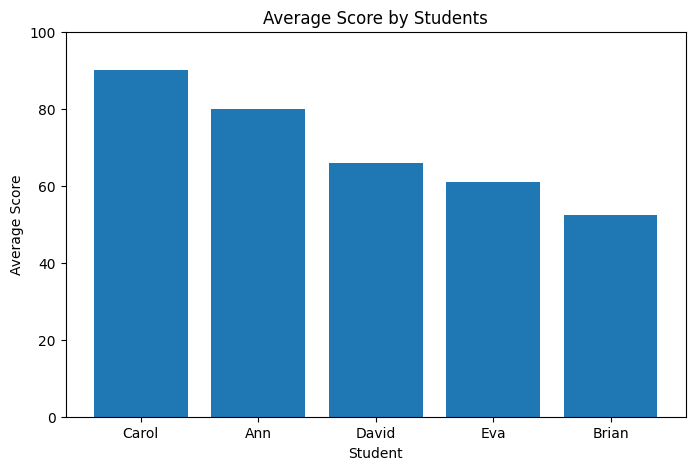

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(df["Student"], df["Average"])

plt.title("Average Score by Students")
plt.xlabel("Student")
plt.ylabel("Average Score")
plt.ylim(0,100)

plt.show()



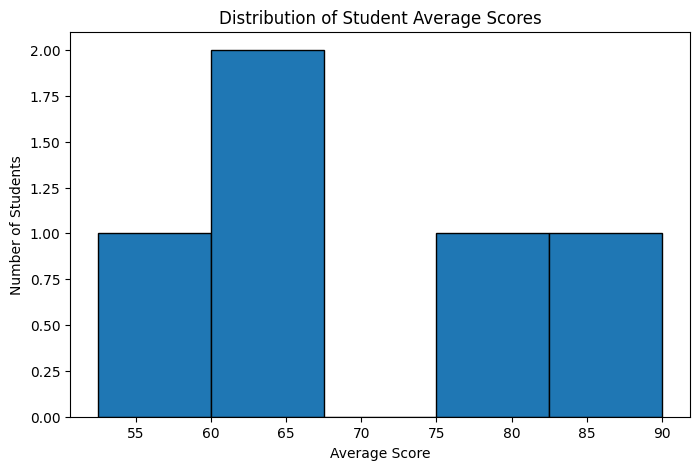

In [14]:
import  matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Average"], bins=5, edgecolor="black")

plt.title("Distribution of Student Average Scores")
plt.xlabel("Average Score")
plt.ylabel("Number of Students")

plt.show()

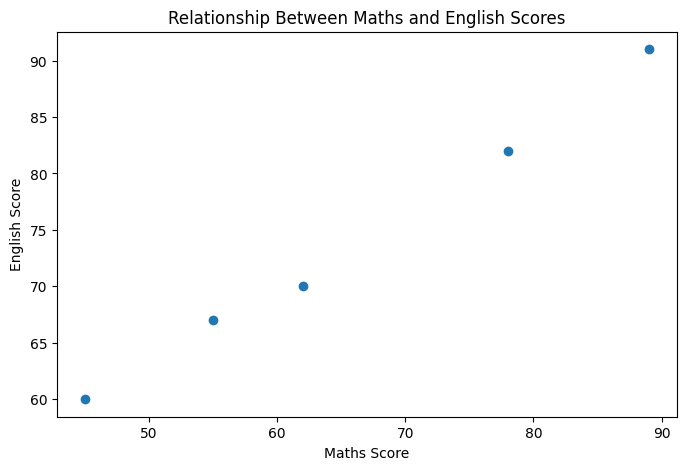

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(df["Maths"], df["English"])

plt.title("Relationship Between Maths and English Scores")
plt.xlabel("Maths Score")
plt.ylabel("English Score")

plt.show()

In [16]:
correlation = df["Maths"].corr(df["English"])

print("Correlation:", correlation)

Correlation: 0.9973172039368385


In [17]:
from sklearn.linear_model import LinearRegression

x=df[["Maths"]]
y=df["English"]

model = LinearRegression()
model.fit(x,y)

print("Model trained successfully!")

Model trained successfully!


In [18]:
new_student = pd.DataFrame({"Maths":[75]})

prediction = model.predict(new_student)

print("Predicted English score:", round(prediction[0], 2))

Predicted English score: 80.43


In [19]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 0.6987527982091462
Intercept: 28.022065877838187


In [20]:
predictions = model.predict(x)

results = df[["Student", "Maths", "English"]].copy()
results["Predicted English"] = predictions.round(2)
results["Predicted Error"] = (results["English"] - results["Predicted English"]
                              ).round(2)

print(results)

  Student  Maths  English  Predicted English  Predicted Error
2   Carol     89       91              90.21             0.79
0     Ann     78       82              82.52            -0.52
3   David     62       70              71.34            -1.34
4     Eva     55       67              66.45             0.55
1   Brian     45       60              59.47             0.53


In [21]:
from sklearn.metrics import mean_absolute_error

mae= mean_absolute_error(y, predictions)

print("Mean Absolute Error:", round(mae,2))

Mean Absolute Error: 0.75


In [22]:
from sklearn.model_selection import train_test_split

x=df[["Maths"]]
y=df["English"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.4,
    random_state=42
)

print("Training examples:", len(x_train))
print("Testing examples:", len(x_test))

Training examples: 3
Testing examples: 2


In [23]:
model= LinearRegression()

model.fit(x_train, y_train)

predictions = model.predict(x_test)

print("Actual English Score:")
print(y_test.to_list())

print("Predicted English scores:")
print(prediction.round(2))

Actual English Score:
[82, 60]
Predicted English scores:
[80.43]


In [24]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, predictions)

print("Mean Absolute Error:", round(mae, 2))

Mean Absolute Error: 0.98


In [25]:
new_student = pd.DataFrame({"Maths": [75]})

predicted_score = model.predict(new_student)

print("Maths score:", 75)
print("Presdicted English score:", round(predicted_score[0], 2))

Maths score: 75
Presdicted English score: 80.6


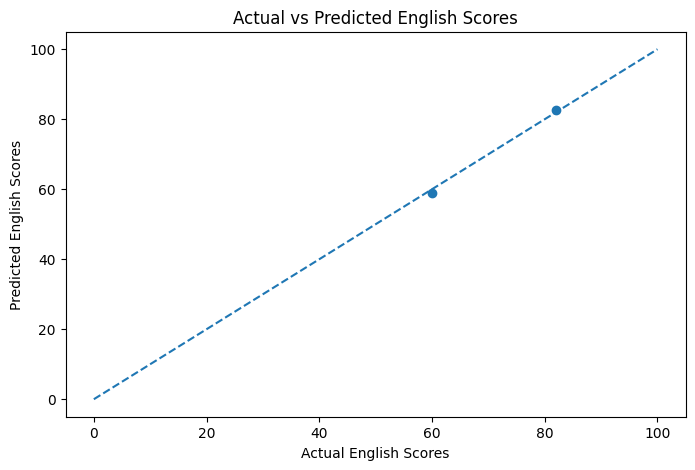

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions)

plt.xlabel("Actual English Scores")
plt.ylabel("Predicted English Scores")
plt.title("Actual vs Predicted English Scores")

plt.plot([0,100], [0,100], linestyle="--")

plt.show()

In [27]:
report = """
STUDENT PERFORMANCE ANALYSIS
Machine Learning Portfolio Project

1. OBJECTIVE
Explore the relationship between students' Maths and English scores.

2. DATASET
The dataset contains five fictional student records.
It includes student names, Maths scores, and English scores.

3. METHODS
-Used Python and pandas to organize and analyze the data.
-Calculated summary statistics and student average.
-Used visualizations to explore score patterns.
-Trained a linear regression model.
-Evaluated predictions using Mean Absolute Error(MAE).

4. FINDINGS
The practice dataset shows a strong positive relationship between Maths and English scores.
Students with higher Maths scores generally had higher English scores in this small dataset.

5. LIMITATIONS
The dataset contains only five fictional students.
The test set is extremely small, so the model's performance cannot be generalized to real students.

6. CONCLUSION
This project demonstrates basic data analysis, visualization, regression, prediction, and model evaluation.

TOOLS
Python, pandas, Matplotlib, and scikit-learn.
"""

print(report)


STUDENT PERFORMANCE ANALYSIS
Machine Learning Portfolio Project

1. OBJECTIVE
Explore the relationship between students' Maths and English scores.

2. DATASET
The dataset contains five fictional student records.
It includes student names, Maths scores, and English scores.

3. METHODS
-Used Python and pandas to organize and analyze the data.
-Calculated summary statistics and student average.
-Used visualizations to explore score patterns.
-Trained a linear regression model.
-Evaluated predictions using Mean Absolute Error(MAE).

4. FINDINGS
The practice dataset shows a strong positive relationship between Maths and English scores.
Students with higher Maths scores generally had higher English scores in this small dataset.

5. LIMITATIONS
The dataset contains only five fictional students.
The test set is extremely small, so the model's performance cannot be generalized to real students.

6. CONCLUSION
This project demonstrates basic data analysis, visualization, regression, prediction,

In [28]:
df.to_csv("student_performance.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [29]:
import joblib

joblib.dump(model,"student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!
